# TP - Image Denoising

In [95]:
import torch, torchvision
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import math

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()
          else "cpu")
)

In [96]:
# Affichage des images
def show_images(*cols, n=10):
    k = len(cols)
    n = min(n, *(t.size(0) for t in cols))
    plt.figure(figsize=(2*k, 2*n))
    for r in range(n):
        for c in range(k):
            ax = plt.subplot(n, k, r*k + c + 1)
            img = cols[c][r]
            if img.dim() == 3 and img.size(0) == 1:
                img = img.squeeze(0)
            ax.imshow(img.detach().to("cpu"), cmap="gray", vmin=0.0, vmax=1.0)
            ax.axis("off")
    plt.tight_layout()
    plt.show()

In [97]:
def add_noise(x, sigma=0.25):
    eps = torch.randn_like(x) * sigma
    return (x + eps).clamp(0.0, 1.0)

def add_noise_sp(x, mass=0.25):
    y = x.clone()
    r = torch.rand_like(x)
    y[r < (mass / 2)] = 0.0
    y[r > 1 - (mass / 2)] = 1.0
    return y

In [98]:
def train_model(model, train_loader, test_loader, criterion, optimizer, epochs=8, gap_threshold=0.05):
    train_hist, test_hist, gap_hist = [], [], []
    overfit_epoch = None

    for ep in range(1, epochs+1):

        # --- Train ---
        model.train()
        tot, n = 0.0, 0
        for x, y in train_loader:
            yhat = model(x)
            if yhat.dim() == 2:   # FCNN / AutoEncoder
                y = flatten(y)

            loss = criterion(yhat, y)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot += loss.item() * x.size(0); n += x.size(0)
        tr_loss = tot / n
        train_hist.append(tr_loss)

        # --- Test ---
        model.eval()
        with torch.no_grad():
            tot, n = 0.0, 0
            for x, y in test_loader:
                yhat = model(x)
                if yhat.dim() == 2:
                    y = flatten(y)
                loss = criterion(yhat, y)
                tot += loss.item() * x.size(0); n += x.size(0)
        te_loss = tot / n
        test_hist.append(te_loss)

        gap = te_loss - tr_loss
        gap_hist.append(gap)

        if overfit_epoch is None:
            if gap > gap_threshold or (len(test_hist)>1 and te_loss>test_hist[-2] and tr_loss<train_hist[-2]):
                overfit_epoch = ep

        print(f"epoch {ep}/{epochs}  train {tr_loss:.4f}  test {te_loss:.4f}  gap {gap:.4f}")

    return train_hist, test_hist, gap_hist, overfit_epoch


In [99]:
# --- Métriques ---
# Différence par rapport à l'originale
def mse(img1, img2):
    return ((img1 - img2) ** 2).mean().item()

# Qualité du signal
def psnr(img1, img2):
    m = mse(img1, img2)
    return 10 * math.log10(1.0 / m) if m > 0 else float('inf')

# Similarité structurel
def ssim(img1, img2, C1=0.01**2, C2=0.03**2):
    mu1 = img1.mean()
    mu2 = img2.mean()
    sigma1 = ((img1 - mu1)**2).mean()
    sigma2 = ((img2 - mu2)**2).mean()
    sigma12 = ((img1 - mu1)*(img2 - mu2)).mean()
    s = (2*mu1*mu2 + C1) * (2*sigma12 + C2)
    d = (mu1**2 + mu2**2 + C1) * (sigma1 + sigma2 + C2)
    return (s / d).item()

# 1/ Dataset (MNIST)

# FCNN

In [100]:
class FCNN(nn.Module):
    def __init__(self, in_size):
        super().__init__()
        sizes = [in_size, 500, 500, in_size]
        layers = []
        for a, b in zip(sizes[:-1], sizes[1:]):
            layers.append(nn.Linear(a, b))
            layers.append(nn.ReLU() if b != in_size else nn.Sigmoid())
        self.model = nn.Sequential(*layers)
    def forward(self, x):
        x = flatten(x)
        return self.model(x)

def flatten(x):
    return x.view(x.size(0), -1)

epoch 1/8  train 0.0391  test 0.0206  gap -0.0185
epoch 2/8  train 0.0177  test 0.0150  gap -0.0027
epoch 3/8  train 0.0141  test 0.0128  gap -0.0013
epoch 4/8  train 0.0124  test 0.0119  gap -0.0005
epoch 5/8  train 0.0114  test 0.0112  gap -0.0002
epoch 6/8  train 0.0107  test 0.0108  gap 0.0001
epoch 7/8  train 0.0102  test 0.0105  gap 0.0002
epoch 8/8  train 0.0098  test 0.0102  gap 0.0003


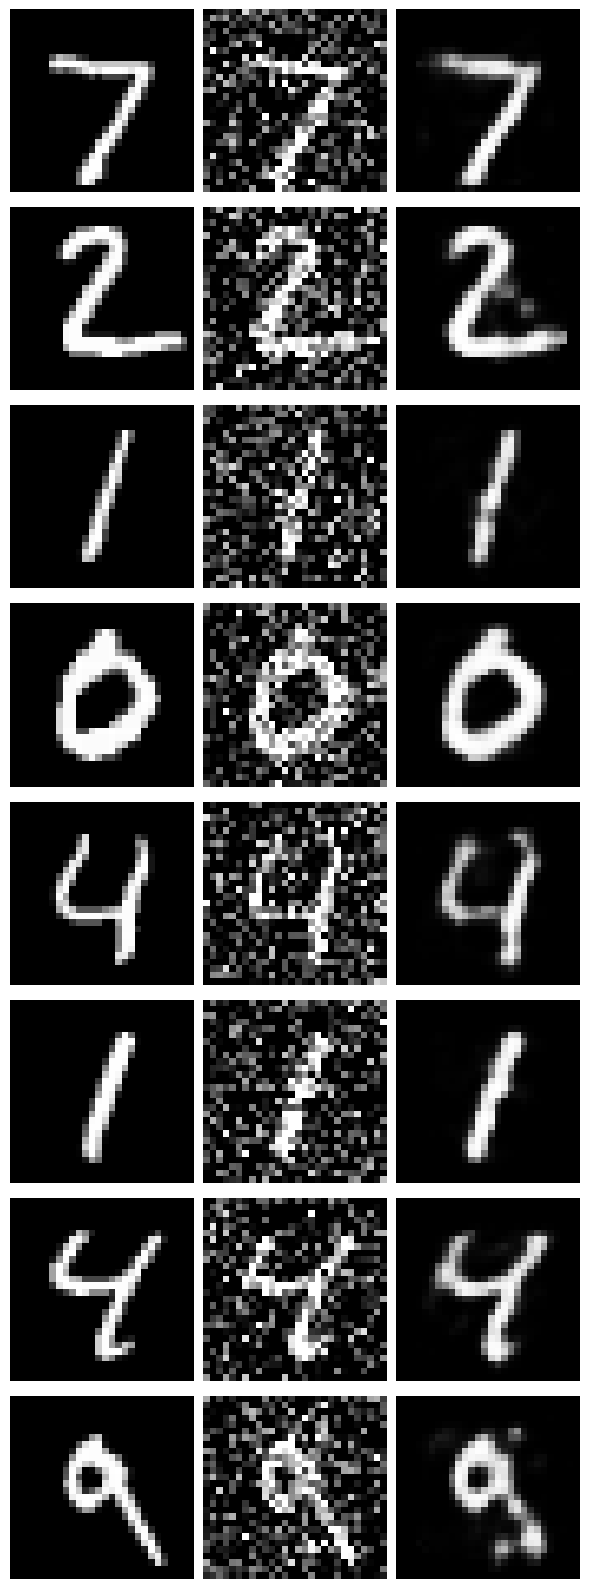

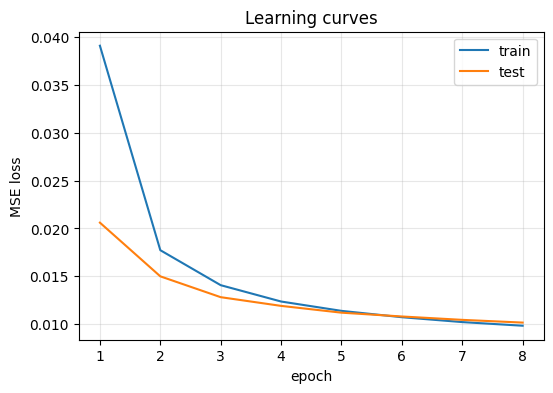

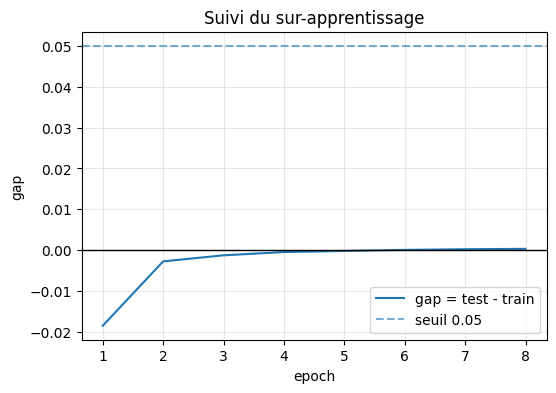

MSE : 0.010427
PSNR: 19.818 dB
SSIM: 0.936


In [101]:
# --- data ---
train_dataset = torchvision.datasets.MNIST(root="trainds", train=True, download=True)
test_dataset  = torchvision.datasets.MNIST(root="testds",  train=False, download=True)

imgs_tr = train_dataset.data.to(device)
imgs_te = test_dataset.data.to(device)
clean_tr = (imgs_tr.to(torch.float32) / 255.0)
clean_te = (imgs_te.to(torch.float32) / 255.0)
noisy_tr = add_noise(clean_tr, sigma=0.4)
noisy_te = add_noise(clean_te, sigma=0.4)

ds_tr = TensorDataset(noisy_tr, clean_tr)
ds_te = TensorDataset(noisy_te, clean_te)
train_loader = DataLoader(ds_tr, batch_size=128, shuffle=True)
test_loader  = DataLoader(ds_te, batch_size=128, shuffle=False)

# --- model / loss / opt ---
model = FCNN(28*28).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# --- train ---
gap_threshold = 0.05
epochs = 8
train_hist, test_hist, gap_hist, overfit_epoch = train_model(
    model, train_loader, test_loader, criterion, optimizer, epochs=epochs, gap_threshold=gap_threshold
)

# --- affichage ---
with torch.no_grad():
    x_noisy, x_clean = next(iter(test_loader))
    x_pred = model(x_noisy).view(-1, 28, 28)
show_images(x_clean, x_noisy, x_pred, n=8)

# --- courbes ---
plt.figure(figsize=(6,4))
plt.plot(range(1, epochs+1), train_hist, label="train")
plt.plot(range(1, epochs+1), test_hist,  label="test")
if overfit_epoch is not None:
    plt.axvline(overfit_epoch, ls="--", alpha=0.6, label=f"overfit@{overfit_epoch}")
plt.xlabel("epoch"); plt.ylabel("MSE loss"); plt.title("Learning curves"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(range(1, epochs+1), gap_hist, label="gap = test - train")
plt.axhline(0.0, color="k", lw=1)
plt.axhline(gap_threshold, ls="--", alpha=0.6, label=f"seuil {gap_threshold}")
if overfit_epoch is not None:
    plt.axvline(overfit_epoch, ls="--", alpha=0.6, label=f"overfit@{overfit_epoch}")
plt.xlabel("epoch"); plt.ylabel("gap"); plt.title("Suivi du sur-apprentissage"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

# --- Evaluation ---
with torch.no_grad():
    x_noisy, x_clean = next(iter(test_loader))
    x_pred = model(x_noisy)
    x_pred = x_pred.view(-1, 1, 28, 28)
    x_clean = x_clean.view(-1, 1, 28, 28)

mse_fcnn = mse(x_pred, x_clean)
psnr_fcnn = psnr(x_pred, x_clean)
ssim_fcnn = ssim(x_pred, x_clean)

print("MSE :", round(mse_fcnn,6))
print("PSNR:", round(psnr_fcnn,3), "dB")
print("SSIM:", round(ssim_fcnn,3))


# AUTO ENCODER

epoch 1/8  train 0.0437  test 0.0247  gap -0.0190
epoch 2/8  train 0.0215  test 0.0185  gap -0.0030
epoch 3/8  train 0.0172  test 0.0158  gap -0.0014
epoch 4/8  train 0.0150  test 0.0140  gap -0.0010
epoch 5/8  train 0.0137  test 0.0132  gap -0.0005
epoch 6/8  train 0.0127  test 0.0126  gap -0.0001
epoch 7/8  train 0.0120  test 0.0119  gap -0.0001
epoch 8/8  train 0.0114  test 0.0116  gap 0.0002


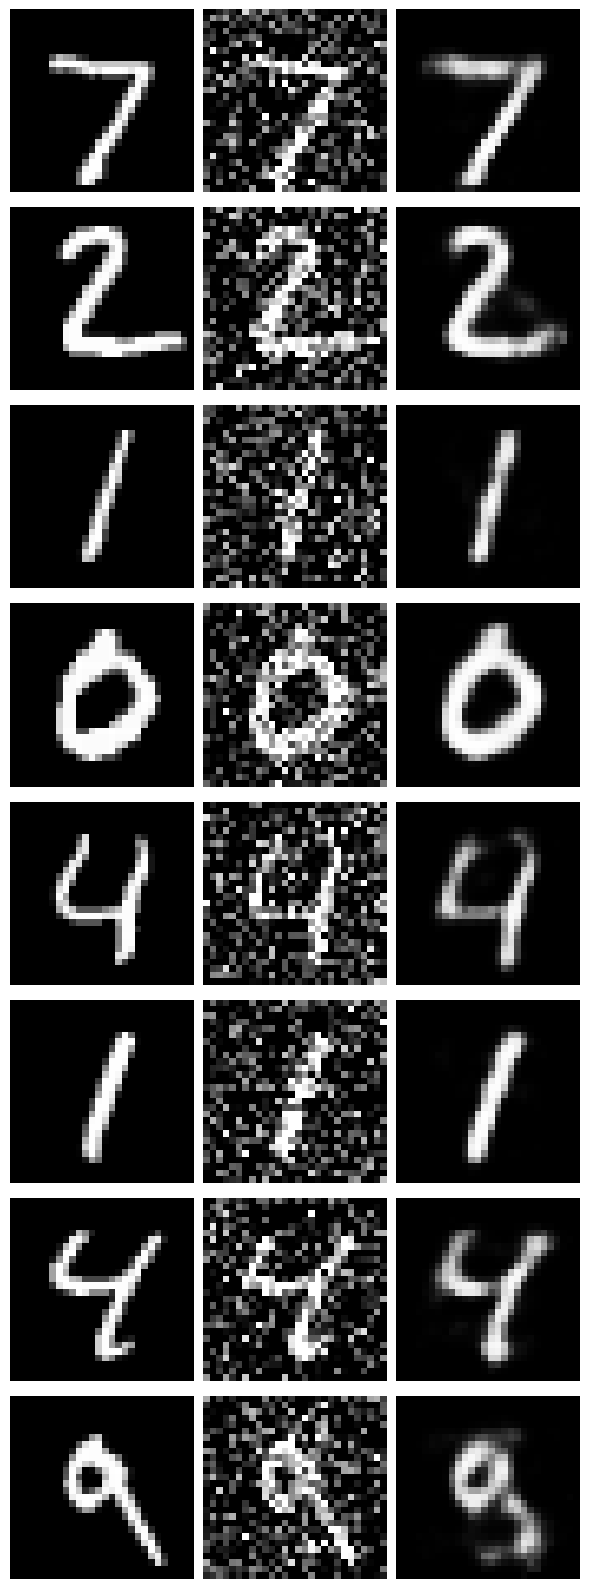

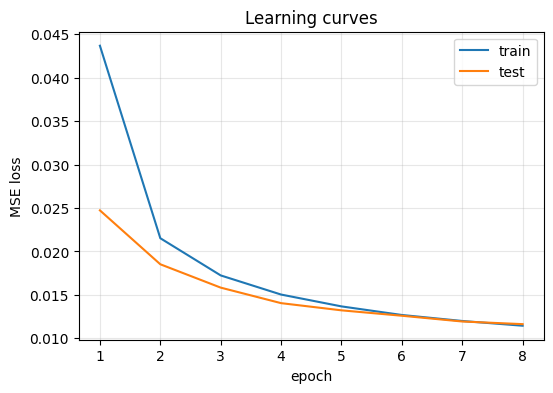

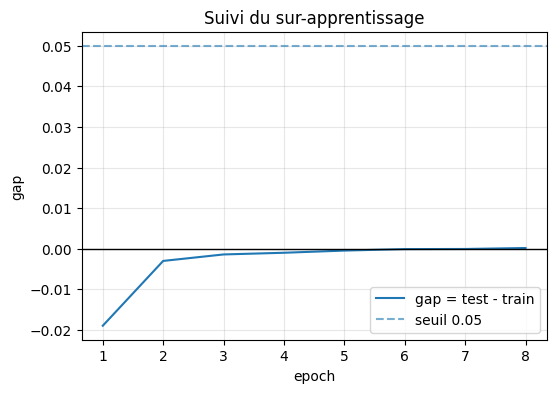

AutoEncoder
MSE : 0.012025
PSNR: 19.199 dB
SSIM: 0.925


In [102]:
class AutoEncoder(nn.Module):
    def __init__(self, in_size, latent=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_size, 500), nn.ReLU(),
            nn.Linear(500, latent), nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent, 500), nn.ReLU(),
            nn.Linear(500, in_size), nn.Sigmoid()
        )
    def forward(self, x):
        x = flatten(x)
        z = self.encoder(x)
        y = self.decoder(z)
        return y

# --- model / loss / opt ---
model = AutoEncoder(28*28, latent=128).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# --- train ---
gap_threshold = 0.05
epochs = 8
train_hist, test_hist, gap_hist, overfit_epoch = train_model(
    model, train_loader, test_loader, criterion, optimizer, epochs=epochs, gap_threshold=gap_threshold
)

# --- affichage ---
with torch.no_grad():
    x_noisy, x_clean = next(iter(test_loader))
    x_pred = model(x_noisy).view(-1,1, 28, 28)
show_images(x_clean, x_noisy, x_pred, n=8)

# --- courbes ---
plt.figure(figsize=(6,4))
plt.plot(range(1, epochs+1), train_hist, label="train")
plt.plot(range(1, epochs+1), test_hist,  label="test")
if overfit_epoch is not None:
    plt.axvline(overfit_epoch, ls="--", alpha=0.6, label=f"overfit@{overfit_epoch}")
plt.xlabel("epoch"); plt.ylabel("MSE loss"); plt.title("Learning curves"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(range(1, epochs+1), gap_hist, label="gap = test - train")
plt.axhline(0.0, color="k", lw=1)
plt.axhline(gap_threshold, ls="--", alpha=0.6, label=f"seuil {gap_threshold}")
if overfit_epoch is not None:
    plt.axvline(overfit_epoch, ls="--", alpha=0.6, label=f"overfit@{overfit_epoch}")
plt.xlabel("epoch"); plt.ylabel("gap"); plt.title("Suivi du sur-apprentissage"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

# --- Evaluation ---
with torch.no_grad():
    x_noisy, x_clean = next(iter(test_loader))
    x_pred = model(x_noisy)              # (N,784)
    x_pred = x_pred.view(-1, 1, 28, 28)  # reshape → image
    x_clean = x_clean.view(-1, 1, 28, 28)

mse_ae = mse(x_pred, x_clean)
psnr_ae = psnr(x_pred, x_clean)
ssim_ae = ssim(x_pred, x_clean)

print("AutoEncoder")
print("MSE :", round(mse_ae,6))
print("PSNR:", round(psnr_ae,3), "dB")
print("SSIM:", round(ssim_ae,3))

# U-NET

In [103]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.net(x)


class UNet(nn.Module):
    def __init__(self, base=32):
        super().__init__()

        # --- Encoder ---
        self.enc1 = DoubleConv(1, base)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = DoubleConv(base, base*2)
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = DoubleConv(base*2, base*4)
        self.pool3 = nn.MaxPool2d(2)

        # --- Bottleneck ---
        self.bot = DoubleConv(base*4, base*8)

        # --- Decoder ---
        self.up3 = nn.ConvTranspose2d(base*8, base*4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(base*8, base*4)

        self.up2 = nn.ConvTranspose2d(base*4, base*2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(base*4, base*2)

        self.up1 = nn.ConvTranspose2d(base*2, base, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(base*2, base)

        # --- sortie ---
        self.out = nn.Conv2d(base, 1, kernel_size=1)

    def forward(self, x):
        def crop(a, b):
            h, w = b.size(2), b.size(3)
            return a[:, :, :h, :w]

        x1 = self.enc1(x)
        x2 = self.enc2(self.pool1(x1))
        x3 = self.enc3(self.pool2(x2))
        xb = self.bot(self.pool3(x3))

        y = self.up3(xb)
        y = torch.cat([y, crop(x3, y)], dim=1)
        y = self.dec3(y)

        y = self.up2(y)
        y = torch.cat([y, crop(x2, y)], dim=1)
        y = self.dec2(y)

        y = self.up1(y)
        y = torch.cat([y, crop(x1, y)], dim=1)
        y = self.dec1(y)

        return torch.sigmoid(self.out(y))

torch.Size([60000, 1, 28, 28]) torch.Size([60000, 1, 28, 28])
epoch 1/6  train 0.0147  test 0.0045  gap -0.0102
epoch 2/6  train 0.0034  test 0.0027  gap -0.0007
epoch 3/6  train 0.0023  test 0.0022  gap -0.0002
epoch 4/6  train 0.0020  test 0.0019  gap -0.0001
epoch 5/6  train 0.0018  test 0.0018  gap 0.0000
epoch 6/6  train 0.0017  test 0.0018  gap 0.0001


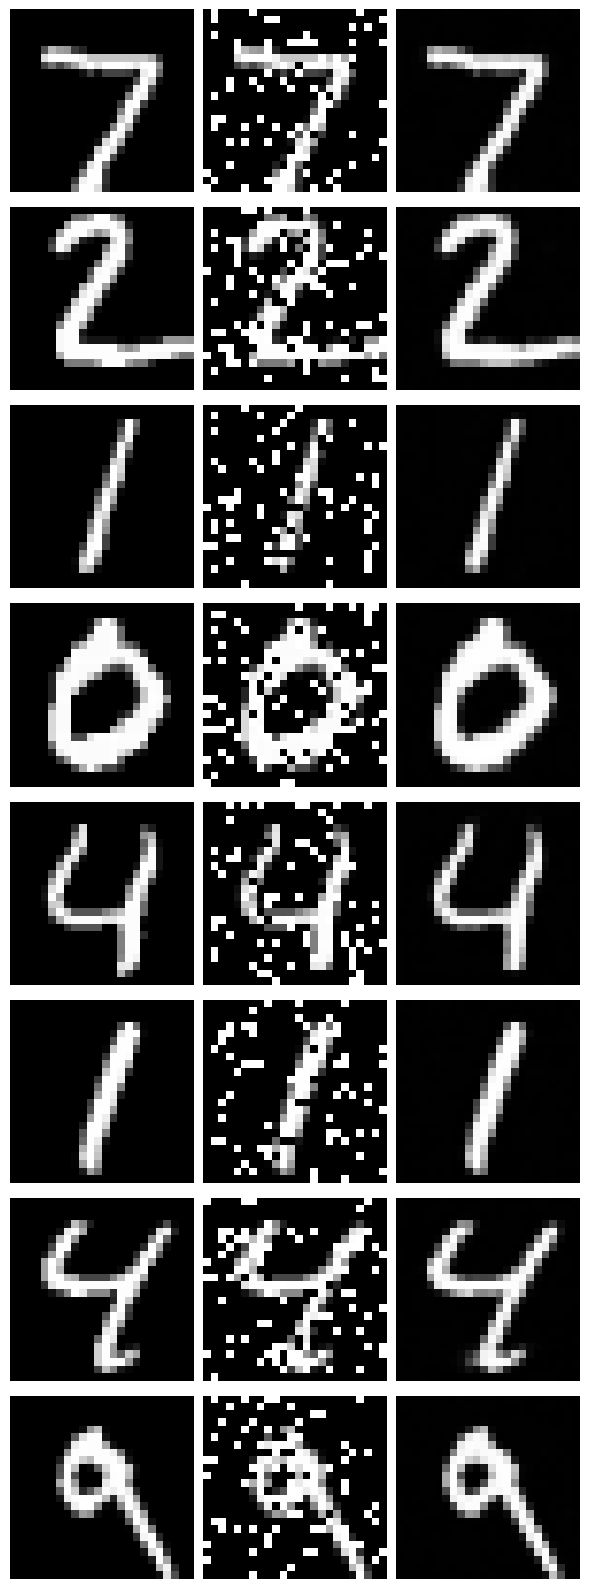

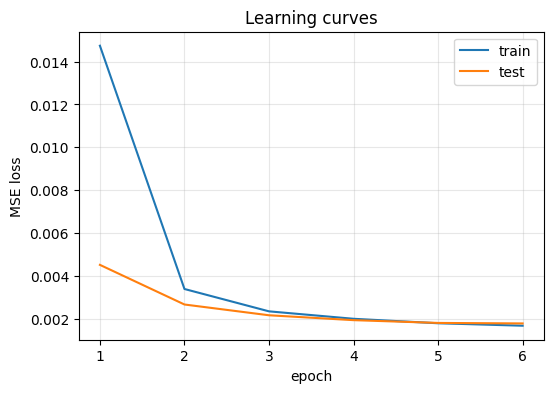

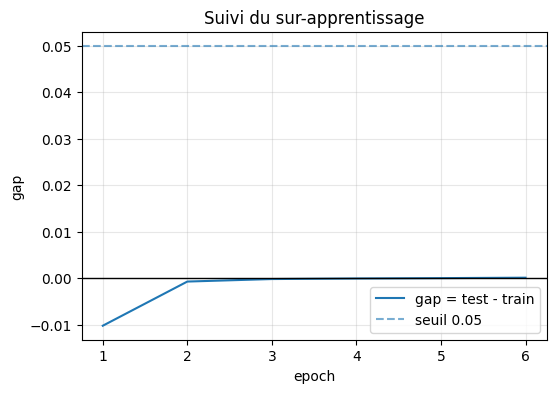

U-Net
MSE : 0.001661
PSNR: 27.795 dB
SSIM: 0.992


In [104]:
# --- Bruit s & p ---
noisy_tr = add_noise_sp(clean_tr, mass=0.25)
noisy_te = add_noise_sp(clean_te, mass=0.25)

clean_tr = clean_tr.reshape(-1, 1, 28, 28)
clean_te = clean_te.reshape(-1, 1, 28, 28)
noisy_tr = noisy_tr.reshape(-1, 1, 28, 28)
noisy_te = noisy_te.reshape(-1, 1, 28, 28)

print(clean_tr.shape, noisy_tr.shape)

# --- Recadrage de 28*28 -> 24*24
clean_tr = clean_tr[:, :, 2:26, 2:26]
clean_te = clean_te[:, :, 2:26, 2:26]
noisy_tr = noisy_tr[:, :, 2:26, 2:26]
noisy_te = noisy_te[:, :, 2:26, 2:26]

# --- Dataset ---
ds_tr = TensorDataset(noisy_tr, clean_tr)
ds_te = TensorDataset(noisy_te, clean_te)
train_loader = DataLoader(ds_tr, batch_size=128, shuffle=True)
test_loader  = DataLoader(ds_te, batch_size=128, shuffle=False)

# --- Modèle, perte, optimisation ---
model = UNet(base=32).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# --- Entraînement ---
epochs = 6
gap_threshold = 0.05
train_hist, test_hist, gap_hist, overfit_epoch = train_model(
    model, train_loader, test_loader, criterion, optimizer,
    epochs=epochs, gap_threshold=gap_threshold
)

# --- Affichage ---
with torch.no_grad():
    x_noisy, x_clean = next(iter(test_loader))
    x_pred = model(x_noisy)
show_images(x_clean, x_noisy, x_pred, n=8)

# --- courbes ---
plt.figure(figsize=(6,4))
plt.plot(range(1, epochs+1), train_hist, label="train")
plt.plot(range(1, epochs+1), test_hist,  label="test")
if overfit_epoch is not None:
    plt.axvline(overfit_epoch, ls="--", alpha=0.6, label=f"overfit@{overfit_epoch}")
plt.xlabel("epoch"); plt.ylabel("MSE loss"); plt.title("Learning curves"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(range(1, epochs+1), gap_hist, label="gap = test - train")
plt.axhline(0.0, color="k", lw=1)
plt.axhline(gap_threshold, ls="--", alpha=0.6, label=f"seuil {gap_threshold}")
if overfit_epoch is not None:
    plt.axvline(overfit_epoch, ls="--", alpha=0.6, label=f"overfit@{overfit_epoch}")
plt.xlabel("epoch"); plt.ylabel("gap"); plt.title("Suivi du sur-apprentissage"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

# --- Evaluation ---
with torch.no_grad():
    x_noisy, x_clean = next(iter(test_loader))
    x_pred = model(x_noisy)  # déjà (N,1,24,24)

mse_unet = mse(x_pred, x_clean)
psnr_unet = psnr(x_pred, x_clean)
ssim_unet = ssim(x_pred, x_clean)

print("U-Net")
print("MSE :", round(mse_unet,6))
print("PSNR:", round(psnr_unet,3), "dB")
print("SSIM:", round(ssim_unet,3))


# Comparaison

In [107]:
import pandas as pd

df = pd.DataFrame({
    "MSE":  [mse_fcnn,  mse_ae,  mse_unet],
    "PSNR (dB)": [psnr_fcnn, psnr_ae, psnr_unet],
    "SSIM": [ssim_fcnn, ssim_ae, ssim_unet],
}, index=["FCNN", "AutoEncoder", "U-Net"]).round({"MSE":6, "PSNR (dB)":3, "SSIM":3})

print(df)

                  MSE  PSNR (dB)   SSIM
FCNN         0.010427     19.818  0.936
AutoEncoder  0.012025     19.199  0.925
U-Net        0.001661     27.795  0.992


# 2/ Dataset CIFAR

# FCNN

epoch 1/8  train 0.0341  test 0.0232  gap -0.0109
epoch 2/8  train 0.0200  test 0.0175  gap -0.0025
epoch 3/8  train 0.0165  test 0.0157  gap -0.0009
epoch 4/8  train 0.0152  test 0.0155  gap 0.0004
epoch 5/8  train 0.0146  test 0.0144  gap -0.0002
epoch 6/8  train 0.0140  test 0.0138  gap -0.0002
epoch 7/8  train 0.0136  test 0.0135  gap -0.0001
epoch 8/8  train 0.0132  test 0.0131  gap -0.0001


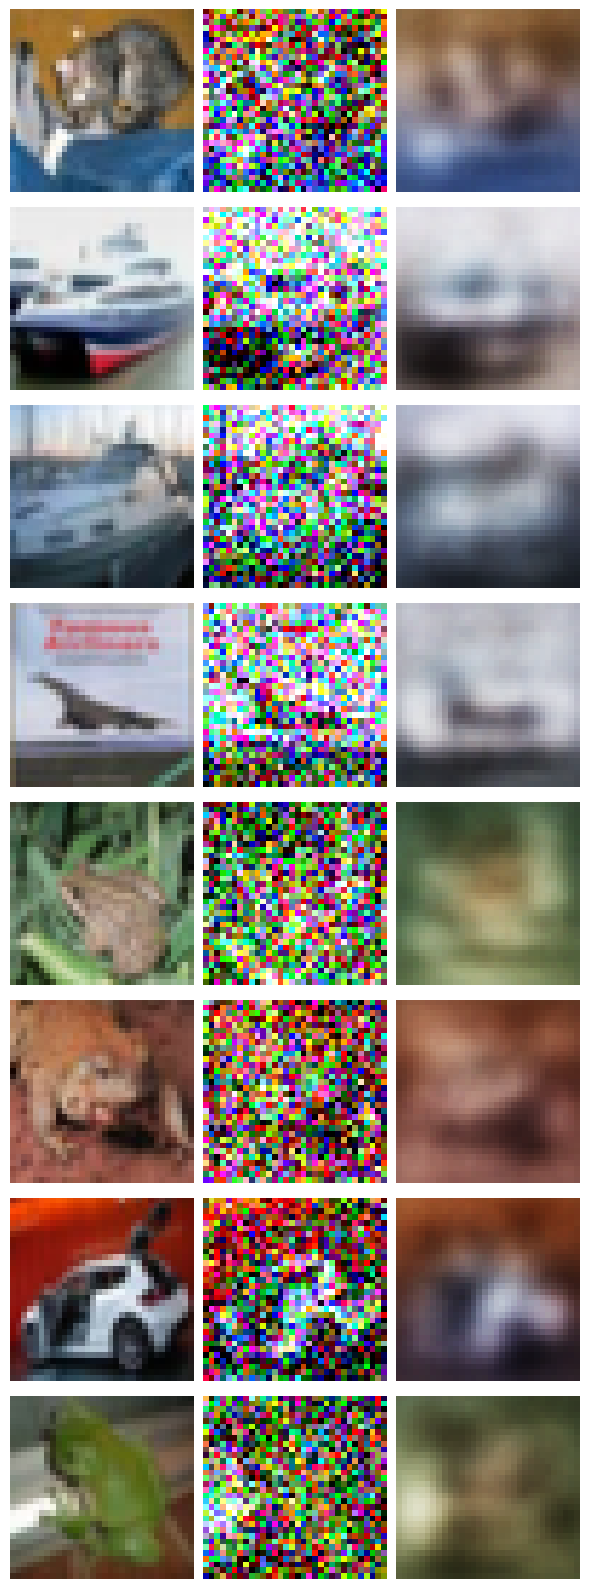

MSE : 0.013235
PSNR: 18.783 dB
SSIM: 0.886


In [118]:
def show_images(*cols, n=10):
    k = len(cols)
    n = min(n, *(t.size(0) for t in cols))
    plt.figure(figsize=(2*k, 2*n))
    for r in range(n):
        for c in range(k):
            ax = plt.subplot(n, k, r*k + c + 1)
            img = cols[c][r]
            # support 1 canal (1xH xW) et 3 canaux (3xH xW)
            if img.dim() == 3:
                if img.size(0) == 1:
                    img = img.squeeze(0)                # HxW
                elif img.size(0) == 3:
                    img = img.permute(1, 2, 0)          # HxW x3
            ax.imshow(img.detach().to("cpu"), cmap="gray" if img.ndim==2 else None,
                      vmin=0.0, vmax=1.0)
            ax.axis("off")
    plt.tight_layout()
    plt.show()

# --- data ---
train_dataset = torchvision.datasets.CIFAR10(root="trainds_cifar", train=True,  download=True)
test_dataset  = torchvision.datasets.CIFAR10(root="testds_cifar",  train=False, download=True)

imgs_tr = torch.tensor(train_dataset.data).permute(0,3,1,2).to(device).float() / 255.0
imgs_te = torch.tensor(test_dataset.data).permute(0,3,1,2).to(device).float() / 255.0

clean_tr = imgs_tr
clean_te = imgs_te

# bruit
noisy_tr = add_noise(clean_tr, sigma=0.4)
noisy_te = add_noise(clean_te, sigma=0.4)

ds_tr = TensorDataset(noisy_tr, clean_tr)
ds_te = TensorDataset(noisy_te, clean_te)
train_loader = DataLoader(ds_tr, batch_size=128, shuffle=True)
test_loader  = DataLoader(ds_te, batch_size=128, shuffle=False)

# --- model / loss / opt ---
model = FCNN(32*32*3).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# --- train ---
gap_threshold = 0.05
epochs = 8
train_hist, test_hist, gap_hist, overfit_epoch = train_model(
    model, train_loader, test_loader, criterion, optimizer,
    epochs=epochs, gap_threshold=gap_threshold
)

# --- affichage ---
with torch.no_grad():
    x_noisy, x_clean = next(iter(test_loader))
    x_pred = model(x_noisy).view(-1, 3, 32, 32)
show_images(x_clean, x_noisy, x_pred, n=8)

# --- Evaluation (mêmes métriques que ton TP) ---
with torch.no_grad():
    x_noisy, x_clean = next(iter(test_loader))
    x_pred = model(x_noisy).view(-1, 3, 32, 32)
mse_fcnn = mse(x_pred, x_clean)
psnr_fcnn = psnr(x_pred, x_clean)
ssim_fcnn = ssim(x_pred, x_clean)

print("MSE :", round(mse_fcnn,6))
print("PSNR:", round(psnr_fcnn,3), "dB")
print("SSIM:", round(ssim_fcnn,3))


# Auto Encoder

epoch 1/8  train 0.0319  test 0.0225  gap -0.0094
epoch 2/8  train 0.0201  test 0.0184  gap -0.0017
epoch 3/8  train 0.0179  test 0.0171  gap -0.0008
epoch 4/8  train 0.0167  test 0.0165  gap -0.0002
epoch 5/8  train 0.0160  test 0.0159  gap -0.0001
epoch 6/8  train 0.0155  test 0.0153  gap -0.0002
epoch 7/8  train 0.0151  test 0.0155  gap 0.0004
epoch 8/8  train 0.0148  test 0.0150  gap 0.0002


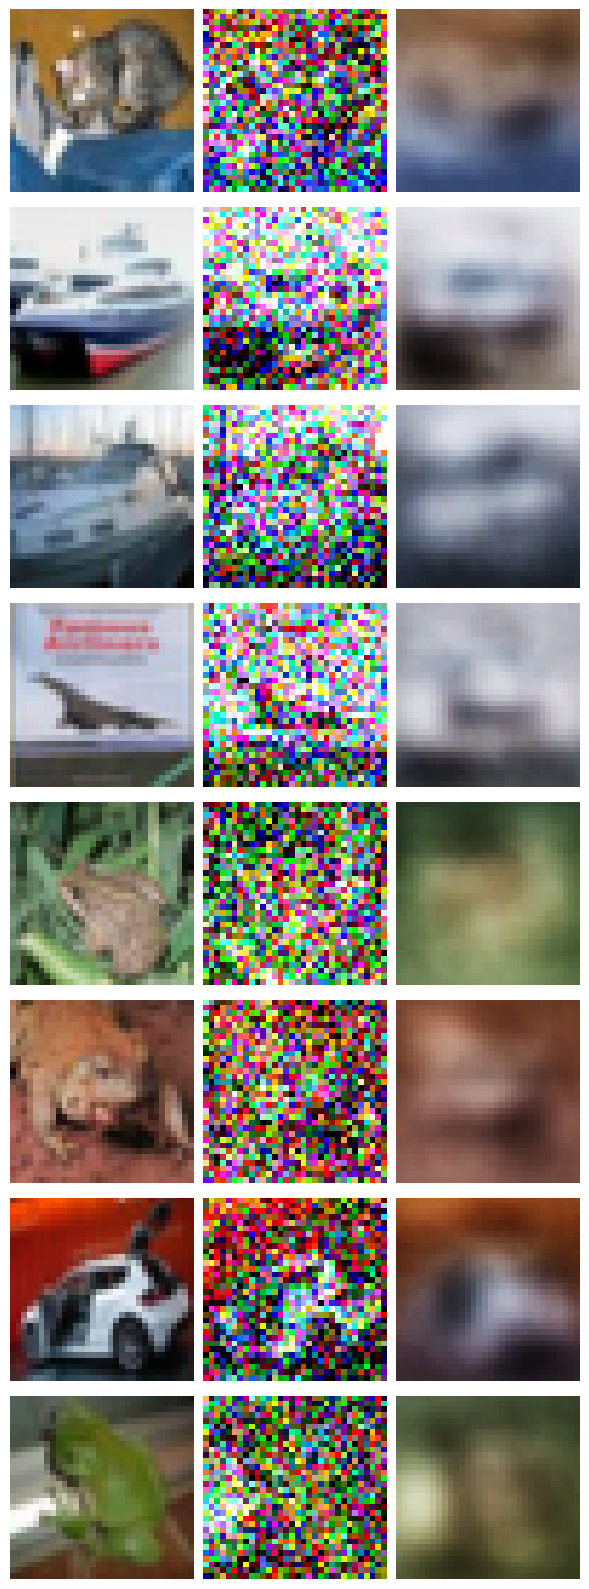

AutoEncoder - CIFAR
MSE : 0.014979
PSNR: 18.245 dB
SSIM: 0.872


In [119]:
model = AutoEncoder(3*32*32, latent=128).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 8
train_hist, test_hist, gap_hist, overfit_epoch = train_model(
    model, train_loader, test_loader, criterion, optimizer, epochs=epochs, gap_threshold=gap_threshold
)

with torch.no_grad():
    x_noisy, x_clean = next(iter(test_loader))
    x_pred = model(x_noisy).view(-1,3,32,32)
show_images(x_clean, x_noisy, x_pred, n=8)

with torch.no_grad():
    x_pred = model(x_noisy).view(-1,3,32,32)

mse_ae = mse(x_pred, x_clean)
psnr_ae = psnr(x_pred, x_clean)
ssim_ae = ssim(x_pred, x_clean)

print("AutoEncoder - CIFAR")
print("MSE :", round(mse_ae,6))
print("PSNR:", round(psnr_ae,3), "dB")
print("SSIM:", round(ssim_ae,3))


# U-NET

torch.Size([50000, 3, 32, 32]) torch.Size([50000, 3, 32, 32])
epoch 1/6  train 0.0069  test 0.0037  gap -0.0032
epoch 2/6  train 0.0022  test 0.0023  gap 0.0002
epoch 3/6  train 0.0013  test 0.0011  gap -0.0002
epoch 4/6  train 0.0010  test 0.0009  gap -0.0001
epoch 5/6  train 0.0009  test 0.0007  gap -0.0002
epoch 6/6  train 0.0007  test 0.0006  gap -0.0001


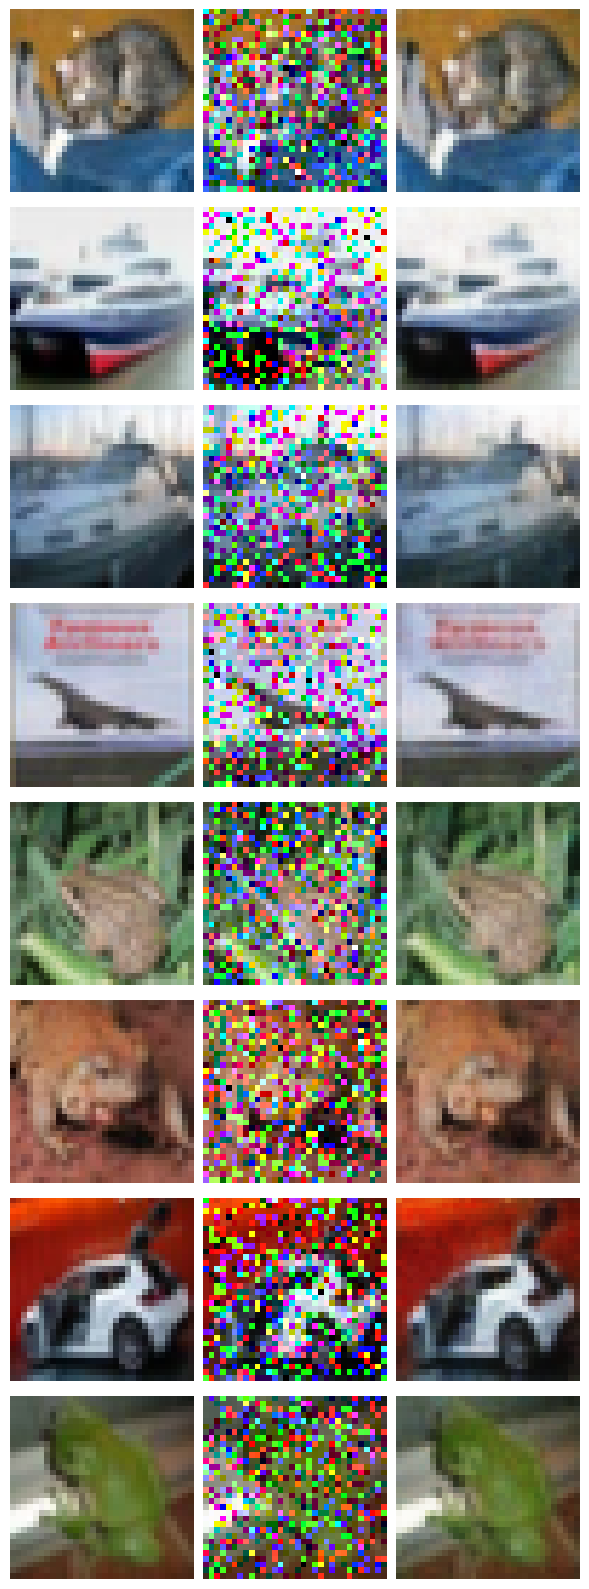

U-Net (CIFAR-10)
MSE : 0.000651
PSNR: 31.863 dB
SSIM: 0.995


In [120]:
# --- Bruit s & p ---
noisy_tr = add_noise_sp(clean_tr, mass=0.25)
noisy_te = add_noise_sp(clean_te, mass=0.25)

print(clean_tr.shape, noisy_tr.shape)

# --- Dataset ---
ds_tr = TensorDataset(noisy_tr, clean_tr)
ds_te = TensorDataset(noisy_te, clean_te)

train_loader = DataLoader(ds_tr, batch_size=128, shuffle=True)
test_loader  = DataLoader(ds_te, batch_size=128, shuffle=False)

# --- Modèle, perte, optimisation ---
model = UNet(base=32)
model.enc1 = DoubleConv(3, 32)
model.out  = nn.Conv2d(32, 3, 1)
model = model.to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# --- Entraînement ---
epochs = 6
gap_threshold = 0.05
train_hist, test_hist, gap_hist, overfit_epoch = train_model(
    model, train_loader, test_loader, criterion, optimizer,
    epochs=epochs, gap_threshold=gap_threshold
)

# --- Affichage ---
with torch.no_grad():
    x_noisy, x_clean = next(iter(test_loader))
    x_pred = model(x_noisy)
show_images(x_clean, x_noisy, x_pred, n=8)

# --- Evaluation ---
with torch.no_grad():
    x_noisy, x_clean = next(iter(test_loader))
    x_pred = model(x_noisy)

mse_unet = mse(x_pred, x_clean)
psnr_unet = psnr(x_pred, x_clean)
ssim_unet = ssim(x_pred, x_clean)

print("U-Net (CIFAR-10)")
print("MSE :", round(mse_unet,6))
print("PSNR:", round(psnr_unet,3), "dB")
print("SSIM:", round(ssim_unet,3))


# Comparaison

In [122]:
import pandas as pd

df = pd.DataFrame({
    "MSE":  [mse_fcnn,  mse_ae,  mse_unet],
    "PSNR (dB)": [psnr_fcnn, psnr_ae, psnr_unet],
    "SSIM": [ssim_fcnn, ssim_ae, ssim_unet],
}, index=["FCNN", "AutoEncoder", "U-Net"]).round({"MSE":6, "PSNR (dB)":3, "SSIM":3})

print(df)

                  MSE  PSNR (dB)   SSIM
FCNN         0.013235     18.783  0.886
AutoEncoder  0.014979     18.245  0.872
U-Net        0.000651     31.863  0.995


# MNIST

FCNN
Réduit bien le bruit gaussien mais perd de l’info spatiale . Qualité correcte mais détails un peu lissés.

AutoEncoder
L’encodeur compresse, donc il garde le gros de la forme mais jette aussi des petits détails. Légèrement en dessous du FCNN.

U-Net
Nettement meilleur. Les convolutions + “skip connections” gardent très bien les bords des chiffres. MSE plus faible que le FCNN.

# CIFAR

FCNN
Plus dur sur des images couleur/variées. Le flattening casse la structure, résultats limités.

AutoEncoder
Même logique que MNIST : le goulot compresse trop pour des scènes couleur, perte de textures/couleurs fines.

U-Net
Plus propre. Texture et couleurs bien conservées. MSE plus faible que le FCNN.

# Conclusion

Quand les images sont simples et en niveaux de gris (MNIST), les MLP (FCNN/AE) s’en sortent bien, mais U-Net reste largement au-dessus.

Sur des images couleur et plus variées (CIFAR), l’écart se creuse fortement : FCNN/AE chutent, U-Net tient très bien grâce aux convolutions et aux sauts.